# Лабораторная работа №3.

### 1. Задача

Длина стержня $L=0{,}5$ м, коэффициент температуропроводности $\alpha=10^{-4}$ м$^2$/с. На левом конце постоянно поддерживается температура $100\ ^\circ$ C
, на правом — $20\ ^\circ$ C.

Начальная температура задаётся формулой

$$T(x,0)=20+80\cos^2\left(\frac{\pi x}{2L}\right).$$

Нужно найти температуру в разные моменты времени, определить время установления и проверить расчёт на более мелкой сетке.

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt

L = 0.5            # длина стержня, м
alpha = 1e-4       # коэффициент температуропроводности, м^2/с
T_left = 100.0     # температура левого конца, градусы Цельсия
T_right = 20.0     # температура правого конца, градусы Цельсия
eps_t = 1e-5       # точность критерия установления, градусы Цельсия в секунду

### 2. Схема

Стержень делится на $N$ равных отрезков. Шаг по координате равен $h=L/N$, шаг по времени — $\tau$. Вводится параметр

$$r=\frac{\alpha\tau}{h^2}.$$

Для внутренних узлов используем неявную схему из лекции:

$$-rT_{i-1}^{n+1}+(1+2r)T_i^{n+1}-rT_{i+1}^{n+1}=T_i^n.$$

На каждом шаге по времени получается трёхдиагональная система. Её удобно решать методом прогонки.

### 3. Метод прогонки

Метод прогонки состоит из прямого и обратного хода. В прямом ходе вычисляются вспомогательные коэффициенты, в обратном — находятся неизвестные температуры. Функция ниже записана отдельно, чтобы её было проще проверить и использовать для обеих сеток.

In [3]:
def progonka(a, b, c, d):
    n = len(d)
    c_new = np.zeros(n)
    d_new = np.zeros(n)

    c_new[0] = c[0] / b[0]
    d_new[0] = d[0] / b[0]

    for i in range(1, n):                       # прямой
        den = b[i] - a[i] * c_new[i - 1]
        if i < n - 1:
            c_new[i] = c[i] / den
        d_new[i] = (d[i] - a[i] * d_new[i - 1]) / den

    x = np.zeros(n)
    x[-1] = d_new[-1]
    for i in range(n - 2, -1, -1):              # обратный
        x[i] = d_new[i] - c_new[i] * x[i + 1]

    return x

### 4. Расчёт температуры во времени

На каждом временном шаге решаем систему только для внутренних узлов. Влияние температур на концах переносится в правую часть. После решения граничные температуры снова задаются равными $100$ и $20\ ^\circ$ C.

Расчёт заканчивается, когда максимальное изменение температуры во внутренних узлах за единицу времени становится меньше $\varepsilon_t$ . Все временные слои сохраняются, чтобы затем построить графики.

In [4]:
def calculate(N, tau):
    h = L / N
    x = np.linspace(0, L, N + 1)
    r = alpha * tau / h**2

    T = 20 + 80 * np.cos(np.pi * x / (2 * L))**2
    T[0] = T_left
    T[-1] = T_right

    history = [T.copy()]
    times = [0.0]

    n_inner = N - 1
    a = np.full(n_inner, -r)
    b = np.full(n_inner, 1 + 2 * r)
    c = np.full(n_inner, -r)

    step = 0
    while True:
        old = T.copy()
        right_part = old[1:-1].copy()
        right_part[0] += r * T_left
        right_part[-1] += r * T_right

        T[1:-1] = progonka(a, b, c, right_part)
        T[0] = T_left
        T[-1] = T_right

        step += 1
        times.append(step * tau)
        history.append(T.copy())

        change = np.max(np.abs((T[1:-1] - old[1:-1]) / tau))
        if change < eps_t:
            break

        if step >= 500000:
            raise RuntimeError('9999999')

    return x, np.array(times), np.array(history), r, change

### 5. Основной расчёт: $N=50$, $\tau=1$ с

Для первой сетки получаем $h=0{,}01$ м. После запуска посмотрим на параметр $r$, число шагов до установления и время установления $t^*=n^*\tau$.

In [5]:
N = 50
tau = 1.0
x, times, history, r, final_change = calculate(N, tau)
t_star = times[-1]

print(f'Число отрезков N = {N}')
print(f'Шаг по координате h = {L / N:.5f} м')
print(f'Шаг по времени tau = {tau:.2f} с')
print(f'r = {r:.3f}')
print(f'Число временных шагов = {len(times) - 1}')
print(f'Время установления t* = {t_star:.2f} с')
print(f'Изменение температуры в последнем шаге = {final_change:.3e} градуса/с')

Число отрезков N = 50
Шаг по координате h = 0.01000 м
Шаг по времени tau = 1.00 с
r = 1.000
Число временных шагов = 608
Время установления t* = 608.00 с
Изменение температуры в последнем шаге = 9.864e-06 градуса/с


### 6. Проверка границ и диапазона температур

По условию температура на концах должна оставаться постоянной. Кроме того, в расчёте не должно появляться странных температур. Проверим эти условия по всем сохранённым слоям.

In [6]:
left_error = np.max(np.abs(history[:, 0] - T_left))
right_error = np.max(np.abs(history[:, -1] - T_right))
min_temp = np.min(history)
max_temp = np.max(history)

print(f'Максимальная ошибка левой границы = {left_error:.3e} градуса')
print(f'Максимальная ошибка правой границы = {right_error:.3e} градуса')
print(f'Минимальная температура во всём расчёте = {min_temp:.6f} градуса')
print(f'Максимальная температура во всём расчёте = {max_temp:.6f} градуса')
print('Граничные условия выполнены:', left_error == 0 and right_error == 0)
print('Температура находится в диапазоне от 20 до 100:', min_temp >= 20 and max_temp <= 100)

Максимальная ошибка левой границы = 0.000e+00 градуса
Максимальная ошибка правой границы = 0.000e+00 градуса
Минимальная температура во всём расчёте = 20.000000 градуса
Максимальная температура во всём расчёте = 100.000000 градуса
Граничные условия выполнены: True
Температура находится в диапазоне от 20 до 100: True


Температура во внутренних узлах должна оставаться между граничными значениями.

### 7. Температура вдоль стержня в разные моменты времени

Построим профили $T(x,t)$ для моментов $0$, $0{,}1t^*$, $0{,}25t^*$, $0{,}5t^*$ и $t^*$. Для каждого момента берётся ближайший сохранённый временной слой.

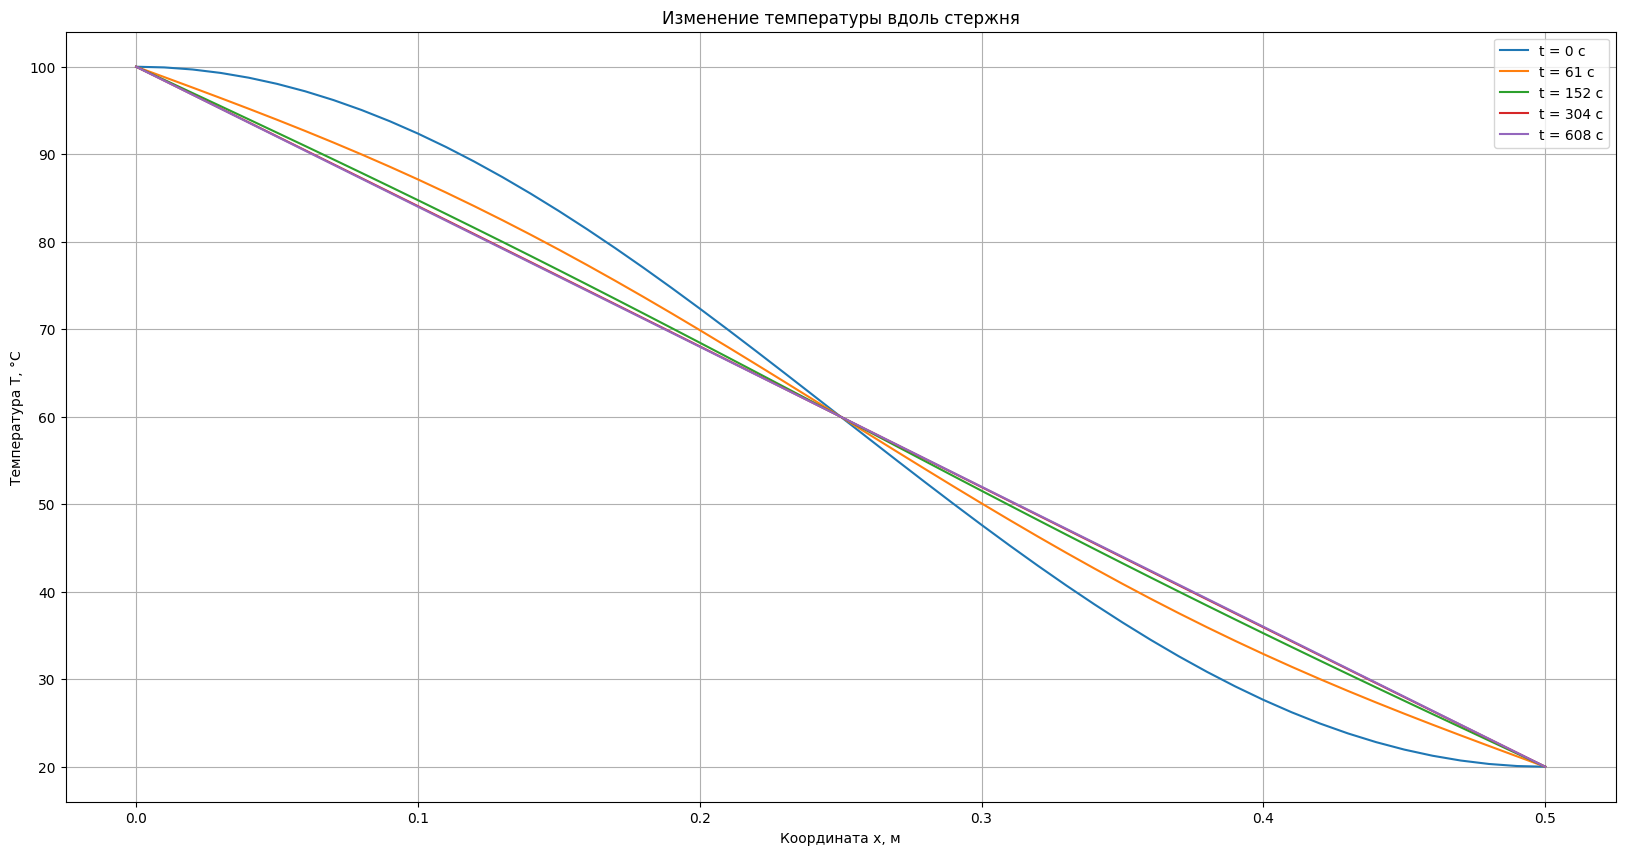

In [7]:
target_times = [0, 0.1 * t_star, 0.25 * t_star, 0.5 * t_star, t_star]

plt.figure(figsize=(20, 10))
for target in target_times:
    j = np.argmin(np.abs(times - target))
    plt.plot(x, history[j], label=f't = {times[j]:.0f} с')

plt.xlabel('Координата x, м')
plt.ylabel('Температура T, °C')
plt.title('Изменение температуры вдоль стержня')
plt.grid(True)
plt.legend()
plt.show()

Со временем кривые приближаются к установившемуся профилю.

### 8. Температура в трёх точках во времени

Посмотрим, как меняется температура в точках $x=L/4$, $x=L/2$ и $x=3L/4$. В первой сетке точки $L/4$ и $3L/4$ не совпадают с узлами, поэтому температуру в этих координатах на каждом временном слое находим линейной интерполяцией.

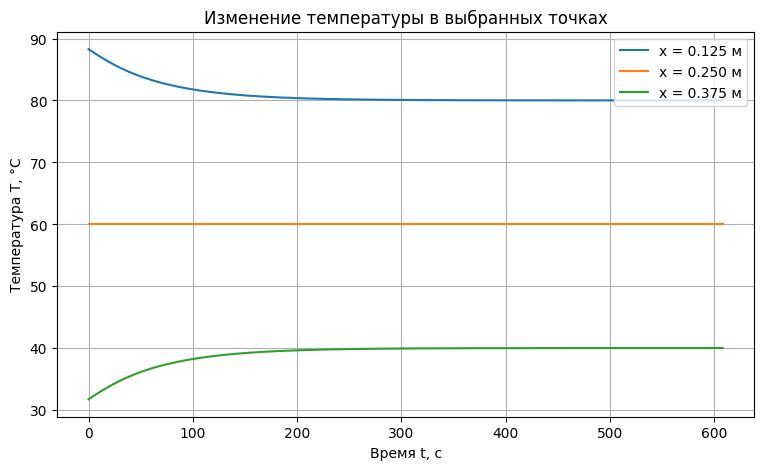

In [8]:
points = [L / 4, L / 2, 3 * L / 4]

plt.figure(figsize=(9, 5))
for point in points:
    values = []
    for row in history:
        values.append(np.interp(point, x, row))
    plt.plot(times, values, label=f'x = {point:.3f} м')

plt.xlabel('Время t, с')
plt.ylabel('Температура T, °C')
plt.title('Изменение температуры в выбранных точках')
plt.grid(True)
plt.legend()
plt.show()

В каждой из трёх точек температура постепенно стабилизируется. Точки ближе к левому концу остаются горячее, потому что на левом конце поддерживается температура 100. Время установления определяется по изменению температуры между соседними временными слоями, а не по достижению конкретной температуры.

### 9. Карта температуры $T(x,t)$

На карте по горизонтали отложена координата $x$, по вертикали — время $t$, а цвет соответствует температуре. Такая карта показывает сразу весь процесс нагрева и охлаждения стержня.

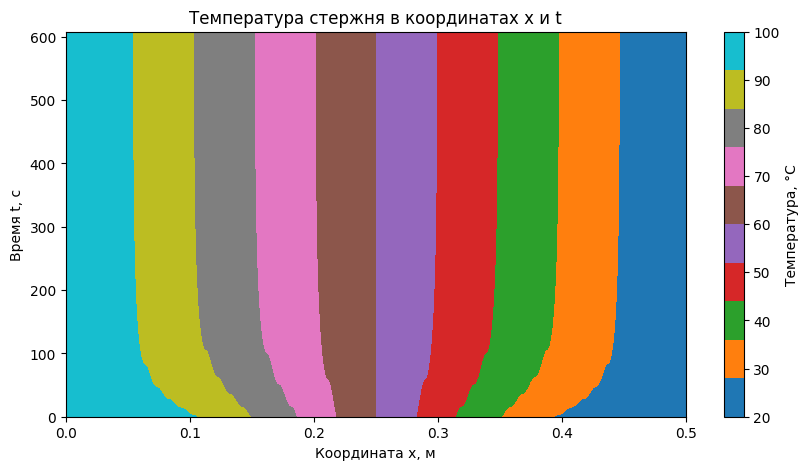

In [17]:
plt.figure(figsize=(10, 5))
plt.imshow(history, origin='lower',cmap='tab10', aspect='auto', extent=[0, L, times[0], times[-1]])
plt.xlabel('Координата x, м')
plt.ylabel('Время t, с')
plt.title('Температура стержня в координатах x и t')
plt.colorbar(label='Температура, °C')
plt.show()

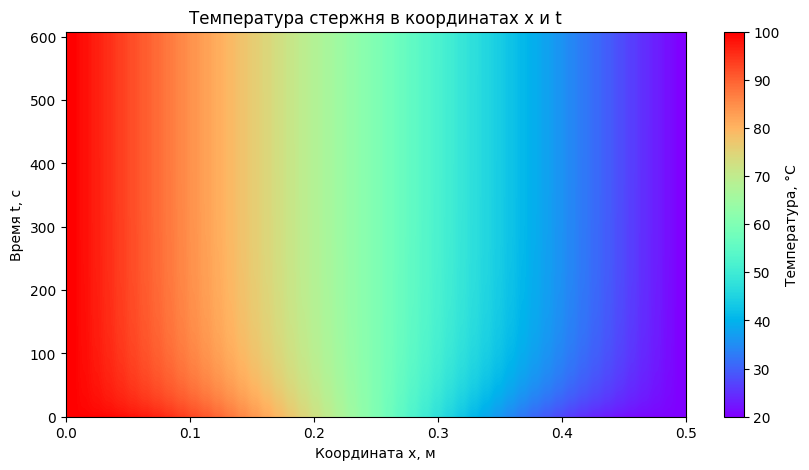

In [19]:
plt.figure(figsize=(10, 5))
plt.imshow(history, origin='lower',cmap='rainbow', aspect='auto', extent=[0, L, times[0], times[-1]])
plt.xlabel('Координата x, м')
plt.ylabel('Время t, с')
plt.title('Температура стержня в координатах x и t')
plt.colorbar(label='Температура, °C')
plt.show()

На карте видно, что влияние граничных температур распространяется внутрь стержня. Постепенно пространственный профиль перестаёт заметно меняться — наступает установившееся состояние.

### 10. Таблица температур в выбранных точках

Выведем температуру в точках $L/4$, $L/2$ и $3L/4$ в моменты $0$, $0{,}25t^*$, $0{,}5t^*$ и $t^*$. Для времени, которое не попало точно на сетку, берётся ближайший временной слой.

In [10]:
table_times = [0, 0.25 * t_star, 0.5 * t_star, t_star]

print('Температура в градусах Цельсия')
print('Время, с'.ljust(14), 'L/4'.rjust(12), 'L/2'.rjust(12), '3L/4'.rjust(12))
for target in table_times:
    j = np.argmin(np.abs(times - target))
    values = [np.interp(point, x, history[j]) for point in points]
    print(f'{times[j]:10.1f}   {values[0]:10.4f}   {values[1]:10.4f}   {values[2]:10.4f}')

Температура в градусах Цельсия
Время, с                L/4          L/2         3L/4
       0.0      88.2703      60.0000      31.7297
     152.0      80.7853      60.0000      39.2147
     304.0      80.0728      60.0000      39.9272
     608.0      80.0006      60.0000      39.9994


### 11. Повторный расчёт на более мелкой сетке

По заданию повторяем расчёт при $N=100$ и $\tau=0{,}5$ с. Тогда $h=0{,}005$ м. Используем тот же критерий установления $10^{-5}\ ^\circ$C/с.

In [11]:
N2 = 100
tau2 = 0.5
x2, times2, history2, r2, final_change2 = calculate(N2, tau2)
t_star2 = times2[-1]

print(f'Число отрезков N = {N2}')
print(f'Шаг по координате h = {L / N2:.5f} м')
print(f'Шаг по времени tau = {tau2:.2f} с')
print(f'r = {r2:.3f}')
print(f'Число временных шагов = {len(times2) - 1}')
print(f'Время установления t* = {t_star2:.2f} с')
print(f'Изменение температуры в последнем шаге = {final_change2:.3e} градуса/с')

Число отрезков N = 100
Шаг по координате h = 0.00500 м
Шаг по времени tau = 0.50 с
r = 2.000
Число временных шагов = 1209
Время установления t* = 604.50 с
Изменение температуры в последнем шаге = 9.977e-06 градуса/с


Сравним установившиеся профили в общих узлах. Каждый узел первой сетки совпадает с каждым вторым узлом второй сетки, поэтому сравнение выполняется напрямую без интерполяции.

Время установления для N=50: 608.00 с
Время установления для N=100: 604.50 с
Максимальная разность установившихся профилей = 5.291116e-06 градуса


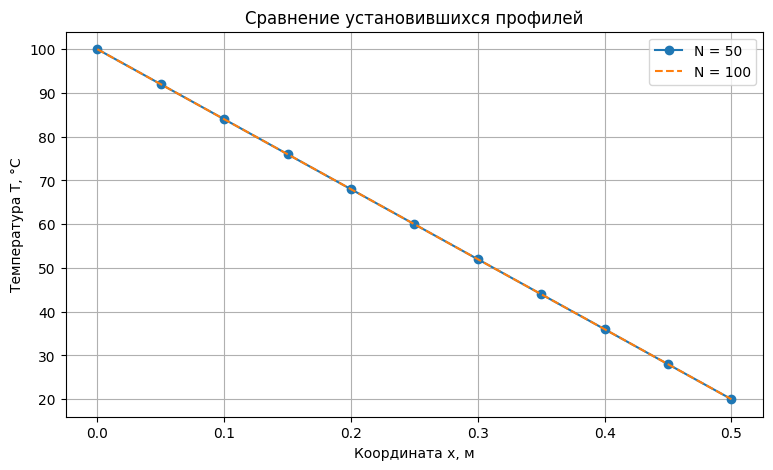

In [12]:
steady1 = history[-1]
steady2_common = history2[-1, ::2]
max_difference = np.max(np.abs(steady1 - steady2_common))

print(f'Время установления для N=50: {t_star:.2f} с')
print(f'Время установления для N=100: {t_star2:.2f} с')
print(f'Максимальная разность установившихся профилей = {max_difference:.6e} градуса')

plt.figure(figsize=(9, 5))
plt.plot(x, steady1, 'o-', markevery=5, label='N = 50')
plt.plot(x2, history2[-1], '--', label='N = 100')
plt.xlabel('Координата x, м')
plt.ylabel('Температура T, °C')
plt.title('Сравнение установившихся профилей')
plt.grid(True)
plt.legend()
plt.show()

### Что показывают полученные числа

Для основной сетки время установления получилось **608 с**. На последнем шаге максимальная скорость изменения температуры равна $9{,}864\cdot10^{-6}$ °C/с, то есть критерий $10^{-5}$ °C/с выполнен.

Для более мелкой сетки получилось **604,5 с**. Эти значения близки: разница составляет 3,5 с. Максимальная разность установившихся профилей в общих узлах — **$5{,}29\cdot10^{-6}$ °C**, поэтому измельчение сетки почти не изменило конечный результат.

Установившийся профиль должен быть близок к прямой $T(x)=100-160x$. Это следует из стационарного уравнения $\frac{d^2T}{dx^2}=0$ и граничных температур. Поэтому ожидаемые значения в точках $L/4$, $L/2$ и $3L/4$ равны 80, 60 и 40 °C. В таблице видно, как температура в первой и третьей точках приближается к 80 и 40 °C. В середине стержня температура остаётся 60 °C из-за симметрии задачи.

Проверки также прошли: температуры на концах не менялись, а температура во всех узлах оставалась в диапазоне от 20 до 100 °C.

### 12. Вывод

По графикам видно, что температура внутри стержня постепенно меняется под действием постоянных температур на концах. В установившемся состоянии профиль близок к прямой между $100\ ^\circ$C и $20\ ^\circ$C. Расчёт проверен по граничным условиям и диапазону температур. Повторный расчёт с $N=100$ и $\tau=0{,}5$ с позволяет оценить влияние измельчения сетки по максимальной разности установившихся профилей.